<a href="https://colab.research.google.com/github/dhomix/vulnerabilidad-hidrica-chiapas-ml/blob/main/vulnerabilidad_hidrica_chiapas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Presentación del proyecto**

## **Abstracto con motivación y audiencia**

En México, el estado de Chiapas, registra **más de 21 mil localidades** en el Censo 2020 y es inviable diagnosticarlas una por una en campo. Este proyecto utiliza los datos abiertos del **Censo de Población y Vivienda 2020 (ITER, INEGI)** para entrenar un modelo de clasificación que identifique localidades con **cobertura de agua entubada inferior a la mediana estatal**, explica con SHAP qué condiciones se asocian a esa menor cobertura y entrega un **mapa interactivo** que apoye la priorización de visitas y elaboración de proyectos.

**Motivación:** pasar de decidir con intuición y cercanía geográfica a decidir con evidencia censal, de manera reproducible y auditable.

**Audiencia:** equipos técnicos y dirección de programas de agua; y evaluadores del bootcamp de Data Science de Coderhouse.

## **Contexto comercial y analítico**

**Contexto de negocio.** Una ONG con recursos limitados debe decidir dónde intervenir primero. Un modelo que ordene las localidades según su probabilidad de rezago hídrico complementa el criterio de campo con información sistemática y permite justificar decisiones ante donantes y comunidades.

**Contexto analítico.**
- **Fuente:** ITER 2020 de Chiapas (INEGI): 21,487 filas y 286 columnas, donde cada fila es una localidad (o un total agregado). Se utilizan 20 columnas: identificadores, coordenadas y 13 variables numéricas.
- **Tarea:** clasificación binaria supervisada. La variable objetivo es `alta_vulnerabilidad_hidrica` (1 = cobertura de agua entubada por debajo de la mediana estatal; 0 = igual o superior).
- **Métrica principal:** **AUC-ROC**, porque el uso real es *ordenar* localidades por riesgo para priorizar, y el AUC mide la calidad de ese ordenamiento sin depender de un umbral. Como métrica secundaria se reporta **F1**.
- **Ingesta:** pipeline local e idempotente con **DuckDB** (`CREATE OR REPLACE TABLE`), de modo que puede ejecutarse varias veces con el mismo resultado.

**Decisiones de diseño (transparencia metodológica).**
1. *Variable objetivo:* una versión preliminar calculaba el porcentaje sobre población total y usaba un umbral fijo, lo que producía un objetivo mal definido y desbalanceado. Se corrigió calculando la cobertura sobre **viviendas particulares habitadas** y dividiendo en la **mediana**, lo que genera clases balanceadas.
2. *Índice de Marginación (CONAPO):* se contempló integrarlo, pero el archivo disponible presentaba corrupción de origen. Se descartó reconstruirlo con valores sintéticos porque no representan datos reales y, además, el indicador de CONAPO sobre viviendas sin agua entubada es casi equivalente a la variable objetivo (**fuga de información**). Por ello **todas las variables provienen del ITER**.
3. *Validación:* se agrupa por municipio para evitar que localidades vecinas, muy parecidas entre sí, queden repartidas entre entrenamiento y validación.

## **Preguntas/Hipótesis a Resolver mediante el Análisis de Datos**

**Preguntas**
1. ¿Es posible predecir, con variables censales, qué localidades tienen una cobertura de agua inferior a la mediana estatal?
2. ¿Qué condiciones (tamaño de la localidad, rezago en otros servicios, ubicación geográfica) se asocian más a esa menor cobertura?
3. ¿Un modelo no lineal aporta una mejora relevante frente a una línea base lineal?

**Hipótesis**
- **H1.** Las localidades más pequeñas y con mayor rezago en vivienda y servicios, tienen menor cobertura de agua.
- **H2.** La altitud y la ubicación geográfica aportan señal predictiva, porque la cobertura depende de las condiciones del territorio y de la infraestructura regional.
- **H3.** Un modelo de boosting o de ensamble de árboles supera de forma clara a una regresión logística.

## **Objetivo**

**General.** Desarrollar y validar un modelo de clasificación que identifique localidades de Chiapas con alta vulnerabilidad hídrica relativa, y explicar sus determinantes para apoyar la priorización de éstas.

**Específicos**
1. Construir una ingesta reproducible con DuckDB y limpiar el ITER 2020.
2. Realizar un análisis exploratorio que identifique patrones y problemas de calidad de datos.
3. Comparar regresión logística, Random Forest y XGBoost con validación agrupada por municipio.
4. Optimizar hiperparámetros del mejor candidato con `GridSearchCV`.
5. Interpretar el modelo con SHAP y generar un mapa interactivo de riesgo.

**Criterio de éxito:** superar claramente la línea base lineal y alcanzar un **AUC > 0.70 en validación agrupada por municipio**.

# **Presentación ejecutiva**

**Link de la presentación ejecutiva (storytelling):** *[pegar aquí el enlace a la presentación]*

**Repositorio público:** *https://github.com/dhomix/vulnerabilidad-hidrica-chiapas-ml*

# **Data Understanding**

## **Configuración del entorno de Python en Google Colab**

Se monta Google Drive (donde está el CSV del ITER) e instalan las librerías que no vienen preinstaladas en Colab: `duckdb` (ingesta), `xgboost` (modelo) y `shap` (explicabilidad). El resto de las dependencias ya forma parte del entorno estándar de Colab.

In [1]:
# CELDA 1 · Configuración del entorno
from google.colab import drive
drive.mount('/content/drive')
!pip install -q duckdb shap xgboost

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## **Librerías necesarias para el análisis de datos**

Se agrupan por función: manipulación de datos (`pandas`, `numpy`, `duckdb`), visualización (`matplotlib`, `seaborn`, `plotly`), modelado (`scikit-learn`, `xgboost`) y explicabilidad (`shap`). Se fija `SEED = 42` para que los resultados sean **reproducibles**.

In [2]:
# CELDA 2 · Librerías
import re, warnings
import numpy as np, pandas as pd, duckdb
import matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px
from sklearn.model_selection import train_test_split, GridSearchCV, GroupKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve, f1_score)
import xgboost as xgb, shap

SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

## **Lectura del dataset**

La tabla base es el **ITER 2020 de Chiapas** (INEGI). Se carga con DuckDB mediante `CREATE OR REPLACE TABLE`, lo que vuelve el proceso **idempotente**: ejecutarlo de nuevo reconstruye la misma tabla sin duplicar datos. Se lee todo como texto (`all_varchar=True`) porque el ITER usa `*` para valores suprimidos por confidencialidad y escribe las coordenadas en grados, minutos y segundos; la conversión a número se hace de forma controlada más adelante.

La celda termina con una **verificación de columnas**: si el INEGI cambia un nombre, el notebook falla con un mensaje claro y no con un error silencioso.

**Resultado:** 21,487 filas y 286 columnas.

In [3]:
RUTA_CSV = '/content/drive/MyDrive/Chiapas - Coder/ITER_07CSV20.csv'
RUTA_DB  = '/content/chiapas.duckdb'   # local de Colab (más estable que Drive)

con = duckdb.connect(RUTA_DB)
con.execute(f"CREATE OR REPLACE TABLE iter_raw AS "
            f"SELECT * FROM read_csv_auto('{RUTA_CSV}', all_varchar=True)")  # idempotente
df_raw = con.execute("SELECT * FROM iter_raw").df()
con.close()
df_raw.columns = df_raw.columns.str.strip().str.lower()
print("Filas y columnas crudas:", df_raw.shape)

NECESARIAS = ['entidad','mun','loc','nom_mun','nom_loc','longitud','latitud','altitud','pobtot',
              'vivpar_hab','vph_aguadv','p_3ymas','p3ym_hli','p_15ymas','p15ym_an','graproes',
              'prom_ocup','vph_pisoti','vph_nodren','vph_s_elec']
faltan = [c for c in NECESARIAS if c not in df_raw.columns]
assert not faltan, f"Columnas no encontradas: {faltan}"

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Filas y columnas crudas: (21487, 286)


## **Análisis inicial del dataset**

Se inspeccionan las primeras filas, los tipos de dato y la presencia de filas agregadas.

**Hallazgos**
- Las primeras filas **no son localidades**: son totales (la fila 0 corresponde al total estatal, con 5,543,828 habitantes) y los grupos "localidades de una vivienda" y "de dos viviendas".
- Todas las columnas están como texto (`object`) por la lectura `all_varchar`. Se convertirán a número en el *wrangling*.
- Hay **330 filas agregadas** que no deben entrar al análisis.
- Las filas de totales no tienen coordenadas (21,157 filas con latitud y longitud), lo que confirma que no son localidades.

In [4]:
display(df_raw[NECESARIAS].head())
df_raw[NECESARIAS].info()
print("Filas agregadas (no son localidades):",
      (df_raw['loc'].isin(['0000','9998','9999']) | (df_raw['mun']=='000')).sum())

,entidad,mun,loc,nom_mun,nom_loc,longitud,latitud,altitud,pobtot,vivpar_hab,vph_aguadv,p_3ymas,p3ym_hli,p_15ymas,p15ym_an,graproes,prom_ocup,vph_pisoti,vph_nodren,vph_s_elec
0,07,000,0000,Total de la entidad Chiapas,Total de la Entidad,None,None,None,5543828,1325555,1207826,5181929,1459648,3745908,512720,7.78,4.09,149481,114526,23972
1,07,000,9998,Total de la entidad Chiapas,Localidades de una vivienda,None,None,None,27985,6905,4851,26490,3610,20062,4180,5.72,3.89,1099,890,1097
2,07,000,9999,Total de la entidad Chiapas,Localidades de dos viviendas,None,None,None,20043,4271,3198,18924,3309,14717,2645,5.7,3.93,845,682,622
3,07,001,0000,Acacoyagua,Total del Municipio,None,None,None,17994,4378,4107,16733,45,11882,1278,7.12,4.08,170,205,94
4,07,001,0001,Acacoyagua,Acacoyagua,"92°40'28.622"" W","15°20'27.475"" N",0081,8092,2076,2074,7557,19,5503,415,7.98,3.84,33,32,20


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21487 entries, 0 to 21486
Data columns (total 20 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   entidad     21487 non-null  object
 1   mun         21487 non-null  object
 2   loc         21487 non-null  object
 3   nom_mun     21487 non-null  object
 4   nom_loc     21487 non-null  object
 5   longitud    21157 non-null  object
 6   latitud     21157 non-null  object
 7   altitud     21157 non-null  object
 8   pobtot      21487 non-null  object
 9   vivpar_hab  21487 non-null  object
 10  vph_aguadv  21487 non-null  object
 11  p_3ymas     21487 non-null  object
 12  p3ym_hli    21487 non-null  object
 13  p_15ymas    21487 non-null  object
 14  p15ym_an    21487 non-null  object
 15  graproes    21487 non-null  object
 16  prom_ocup   21487 non-null  object
 17  vph_pisoti  21487 non-null  object
 18  vph_nodren  21487 non-null  object
 19  vph_s_elec  21487 non-null  object
dtypes: obj

## **Descripción de variables**

| Variable | Descripción | Rol |
|---|---|---|
| `entidad`, `mun`, `loc` | Claves geoestadísticas (se concatenan en `cvegeo`, de 9 dígitos) | Identificador |
| `nom_mun`, `nom_loc` | Nombre de municipio y de localidad | Etiqueta (mapa) |
| `latitud`, `longitud` | Coordenadas en grados-minutos-segundos (se convierten a decimal) | Predictor |
| `altitud` | Altitud sobre el nivel del mar (m) | Predictor |
| `pobtot` | Población total | Predictor (transformada) |
| `vivpar_hab` | Viviendas particulares habitadas | Denominador |
| `vph_aguadv` | Viviendas particulares habitadas con agua entubada | **Base del objetivo** |
| `vph_pisoti` | Viviendas con piso de tierra | Predictor (como %) |
| `vph_nodren` | Viviendas sin drenaje | Predictor (como %) |
| `vph_s_elec` | Viviendas sin electricidad | Predictor (como %) |
| `p_3ymas`, `p3ym_hli` | Población de 3 años y más, y la que habla lengua indígena | Predictor (como %) |
| `p_15ymas`, `p15ym_an` | Población de 15 años y más, y la analfabeta | Predictor (como %) |
| `graproes` | Grado promedio de escolaridad | Predictor |
| `prom_ocup` | Promedio de ocupantes por vivienda | Predictor |

**Variables derivadas** (ver *Feature Engineering*): `pct_agua_viv`, `pct_piso_tierra`, `pct_sin_drenaje`, `pct_sin_elec`, `pct_hli`, `pct_analf`, `log_pobtot`, `rango_pob` y la variable objetivo `alta_vulnerabilidad_hidrica`.

**Nota:** los nombres de columna siguen el diccionario de datos del ITER 2020 del INEGI, que debe consultarse como referencia oficial.

# **Data Wrangling - Limpieza y transformación de datos**

El ITER mezcla localidades con totales, usa símbolos de supresión y escribe coordenadas como texto. Antes de analizar hay que: (1) eliminar filas que no son localidades, (2) convertir texto a números y (3) convertir coordenadas a grados decimales.

## **Funciones auxiliares**

- `a_numerico`: convierte a número y trata `*`, `N/D` y vacíos como nulos. En el ITER, `*` indica un dato suprimido por confidencialidad.
- `dms_a_decimal`: convierte, por ejemplo, `92°40'28.622" W` a `-92.6746`. El hemisferio oeste recibe signo negativo, requisito para que Chiapas quede en el lugar correcto del mapa.

In [5]:
# CELDA · Funciones
def a_numerico(s):
    s = (s.astype(str).str.strip()
          .replace(['*','N/D','n/d','ND','','-','nan','None'], np.nan)
          .str.replace(',', '', regex=False))
    return pd.to_numeric(s, errors='coerce')

def dms_a_decimal(v):
    if pd.isna(v): return np.nan
    t = str(v).strip()
    try: return float(t)
    except ValueError: pass
    p = re.findall(r"[\d.]+", t)
    if not p: return np.nan
    g, m, s = (list(map(float, p)) + [0, 0])[:3]
    d = g + m/60 + s/3600
    return -d if (re.search(r"[WwOoSs]", t) or t.startswith("-")) else d

## **Valores duplicados**

Se eliminan las **330 filas agregadas**: el total estatal, los grupos de localidades de una y de dos viviendas (claves `9998` y `9999`) y los totales municipales (`loc = 0000`). Dejarlas mezclaría totales con localidades individuales; por ejemplo, el total del estado tiene 5.5 millones de habitantes.

**Resultado:** quedan **21,157 localidades** y **0 duplicados** en `cvegeo`, por lo que cada fila corresponde a una localidad única.

In [6]:
# CELDA · Duplicados y filas agregadas
df = df_raw.copy()
df['mun'] = df['mun'].str.zfill(3); df['loc'] = df['loc'].str.zfill(4)
df['cvegeo'] = df['entidad'].str.zfill(2) + df['mun'] + df['loc']

agregados = df['loc'].isin(['0000','9998','9999']) | (df['mun'] == '000')
print(f"Filas agregadas eliminadas: {agregados.sum()}")
df = df[~agregados].reset_index(drop=True)
print("cvegeo duplicados:", df['cvegeo'].duplicated().sum())

Filas agregadas eliminadas: 330
cvegeo duplicados: 0


## **Valores nulos y otras transformaciones (tipos y coordenadas)**

Se convierten las variables a numéricas y las coordenadas a decimal, y se valida que caigan dentro de Chiapas (latitud 14 a 18, longitud -94.5 a -90).

**Hallazgos**
- **Coordenadas:** 0 inválidas y 0 nulas. `altitud` y `pobtot` tampoco tienen nulos.
- **43.4% de nulos, idéntico en todas las variables de vivienda y población.** Que el porcentaje sea el mismo indica que son **las mismas filas**: localidades de 1 o 2 viviendas, cuyos datos el INEGI suprime por confidencialidad. No es un faltante aleatorio.

**Decisión: no imputar, excluir del modelado.** Imputar fabricaría la variable objetivo para casi la mitad de las localidades y, como las coordenadas son predictores, el modelo terminaría "aprendiendo" la imputación en lugar de la realidad.

**Impacto de la decisión.** Se excluyen aproximadamente 9.4 mil localidades (44%), pero representan una fracción mínima de la población: los grupos de una y dos viviendas del ITER suman 27,985 + 20,043 = **48,028 personas, cerca de 0.9% del estado** (5,543,828). La limitación importante es que se trata de viviendas muy aisladas, posiblemente entre las más rezagadas, y el modelo **no las cubre**.

In [7]:
# CELDA · Nulos y '*' (tipos y coordenadas)
num_cols = ['altitud','pobtot','vivpar_hab','vph_aguadv','p_3ymas','p3ym_hli','p_15ymas',
            'p15ym_an','graproes','prom_ocup','vph_pisoti','vph_nodren','vph_s_elec']
for c in num_cols:
    df[c] = a_numerico(df[c])

df['latitud']  = df['latitud'].apply(dms_a_decimal)
df['longitud'] = df['longitud'].apply(dms_a_decimal)
df.loc[df['longitud'] > 0, 'longitud'] *= -1
fuera = ~df['latitud'].between(14.0, 18.0) | ~df['longitud'].between(-94.5, -90.0)
df.loc[fuera, ['latitud','longitud']] = np.nan
print("Coordenadas inválidas:", fuera.sum())
print(df[num_cols + ['latitud','longitud']].isna().mean().round(3))

Coordenadas inválidas: 0
altitud       0.000
pobtot        0.000
vivpar_hab    0.434
vph_aguadv    0.434
p_3ymas       0.434
p3ym_hli      0.434
p_15ymas      0.434
p15ym_an      0.434
graproes      0.434
prom_ocup     0.434
vph_pisoti    0.434
vph_nodren    0.434
vph_s_elec    0.434
latitud       0.000
longitud      0.000
dtype: float64


## **Verificación de valores outliers**

Se aplica la regla del rango intercuartílico (IQR).

- `altitud`: 637 valores atípicos (3.0%).
- `pobtot`: 2,811 valores atípicos (13.3%).

**Decisión: se detectan y documentan, pero no se recortan.** Los valores altos de altitud corresponden a la zona alta de Chiapas (hasta cerca de 3,000 m) y los de población a ciudades; son datos reales y recortarlos eliminaría información. La fuerte asimetría de `pobtot` se maneja con la transformación logarítmica, y los modelos basados en árboles son robustos a valores extremos.

altitud: 637 valores fuera de [Q1-1.5·IQR, Q3+1.5·IQR] (3.0%)
pobtot: 2811 valores fuera de [Q1-1.5·IQR, Q3+1.5·IQR] (13.3%)


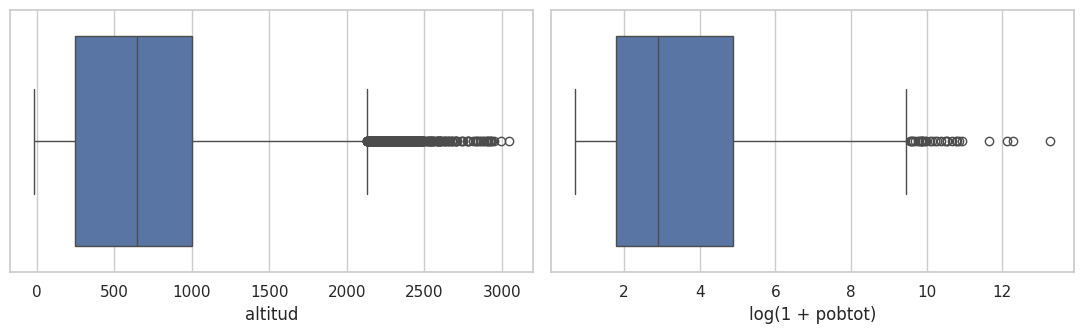

In [8]:
# CELDA · Outliers: se DETECTAN y documentan, no se recortan
for col in ['altitud','pobtot']:
    q1, q3 = df[col].quantile([.25, .75]); iqr = q3 - q1
    n = ((df[col] < q1 - 1.5*iqr) | (df[col] > q3 + 1.5*iqr)).sum()
    print(f"{col}: {n} valores fuera de [Q1-1.5·IQR, Q3+1.5·IQR] ({n/len(df):.1%})")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.boxplot(x=df['altitud'], ax=ax[0]); sns.boxplot(x=np.log1p(df['pobtot']), ax=ax[1])
ax[1].set_xlabel("log(1 + pobtot)"); plt.tight_layout(); plt.show()

# **Feature Engineering**

## **Creación de nuevas columnas o medidas**

Las cuentas absolutas dependen del tamaño de la localidad, por lo que se convierten en **porcentajes** que sí son comparables entre localidades pequeñas y grandes:

- `pct_agua_viv` = viviendas con agua entubada / viviendas habitadas. **Es la base del objetivo.** Se limita a [0, 100].
- `pct_piso_tierra`, `pct_sin_drenaje`, `pct_sin_elec`: porcentaje de viviendas con cada carencia.
- `pct_hli`, `pct_analf`: porcentaje de población que habla lengua indígena y de población analfabeta (sobre su grupo de edad).
- `log_pobtot`: logaritmo de la población, para corregir la asimetría.
- `rango_pob`: variable **categórica** del tamaño de la localidad (0 a 49, 50 a 249, 250 a 999 y 1000 o más habitantes).

**Variable objetivo.** `alta_vulnerabilidad_hidrica = 1` si la cobertura de la localidad es **menor a la mediana estatal**. La mediana resultó de **98.0%**, y la partición genera clases perfectamente balanceadas (50% / 50%). Solo se modelan las **11,772 localidades** con dato de agua (se excluyen las 9,385 sin dato o sin viviendas habitadas).

In [9]:
def pct(num, den):
    return (num / den.where(den > 0) * 100).replace([np.inf, -np.inf], np.nan)

df['pct_agua_viv']    = pct(df['vph_aguadv'], df['vivpar_hab']).clip(0, 100)   # base del objetivo
df['pct_piso_tierra'] = pct(df['vph_pisoti'], df['vivpar_hab'])
df['pct_sin_drenaje'] = pct(df['vph_nodren'], df['vivpar_hab'])
df['pct_sin_elec']    = pct(df['vph_s_elec'], df['vivpar_hab'])
df['pct_hli']         = pct(df['p3ym_hli'], df['p_3ymas'])
df['pct_analf']       = pct(df['p15ym_an'], df['p_15ymas'])
df['log_pobtot']      = np.log1p(df['pobtot'])
df['rango_pob'] = pd.cut(df['pobtot'], [-1, 49, 249, 999, np.inf],
                         labels=['0_49','50_249','250_999','1000_mas']).astype(str)

# Localidades modelables = con dato de agua (las suprimidas por secreto estadístico se excluyen)
df_m = df.dropna(subset=['pct_agua_viv']).copy()
print(f"Totales: {len(df):,} | modelables: {len(df_m):,} | excluidas: {len(df)-len(df_m):,}")

mediana = df_m['pct_agua_viv'].median()
df_m['alta_vulnerabilidad_hidrica'] = (df_m['pct_agua_viv'] < mediana).astype(int)
print(f"Mediana estatal de cobertura: {mediana:.1f}%")
print(df_m['alta_vulnerabilidad_hidrica'].value_counts(normalize=True).round(3))

Totales: 21,157 | modelables: 11,772 | excluidas: 9,385
Mediana estatal de cobertura: 98.0%
alta_vulnerabilidad_hidrica
0    0.5
1    0.5
Name: proportion, dtype: float64


### **Lectura crítica de la variable objetivo**

La mediana de **98%** advierte algo importante: la cobertura está muy concentrada cerca del 100%. Por eso la clase 1 ("alta vulnerabilidad") significa **"menos cobertura que la localidad típica"**, y no necesariamente una situación crítica; una localidad con 95% queda en la clase 1.

Esto no invalida el modelo, porque sirve para **ordenar** localidades por riesgo, pero conviene leerlo así. Las localidades verdaderamente críticas (cobertura cercana a 0%) son un subconjunto que se aprecia en el histograma del EDA. Un siguiente paso natural es probar umbrales normativos (por ejemplo, menos de 80% o menos de 50%) o un objetivo ordinal.

# **Análisis Exploratorio de datos**

Se trabaja sobre las 11,772 localidades modelables y se usa la cobertura **continua** (`pct_agua_viv`) para no depender de la definición del objetivo binario.

## **Análisis univariado**

Distribución de la cobertura de agua, el tamaño de la localidad (en escala logarítmica), la altitud y el porcentaje de viviendas con piso de tierra.

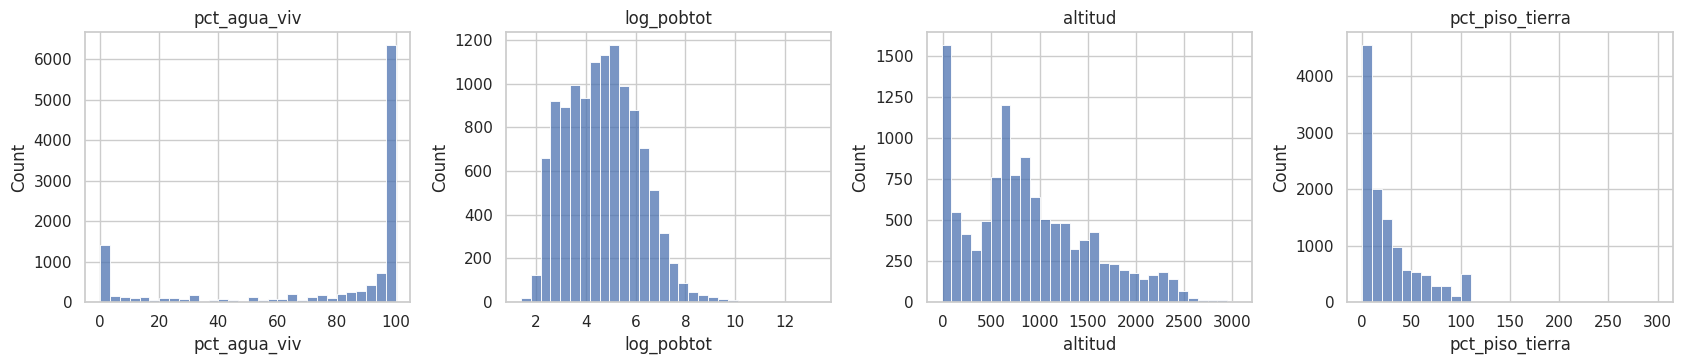

In [10]:
# Univariado
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
for a, c in zip(ax, ['pct_agua_viv','log_pobtot','altitud','pct_piso_tierra']):
    sns.histplot(df_m[c].dropna(), bins=30, ax=a); a.set_title(c)
plt.tight_layout(); plt.show()

**Lectura**
- **`pct_agua_viv` está polarizada.** Hay una masa enorme cerca de 100% (aproximadamente 6,300 localidades) y un segundo grupo en **0%** (cerca de 1,400 localidades), con pocos casos intermedios. Es la distribución que explica la mediana de 98%. Las lecturas son aproximadas, tomadas del histograma.
- **`log_pobtot`** tiene forma de campana, con la mayoría de localidades entre unas decenas y unos cientos de habitantes: predominan las comunidades pequeñas.
- **`altitud`** concentra muchas localidades cerca del nivel del mar y tiene una cola larga hasta cerca de 3,000 m.
- **`pct_piso_tierra`** se concentra cerca de 0%, pero el eje llega a **~300%**, lo cual es imposible para un porcentaje de viviendas. Es una **inconsistencia de origen del ITER** (más viviendas con piso de tierra que viviendas habitadas registradas) que se documenta como limitación de calidad de datos. Su efecto en el modelo es acotado, porque los árboles dependen del orden de los valores y no de su magnitud exacta.

## **Análisis bivariado**

Relación de la cobertura con el tamaño de la localidad y con la altitud.

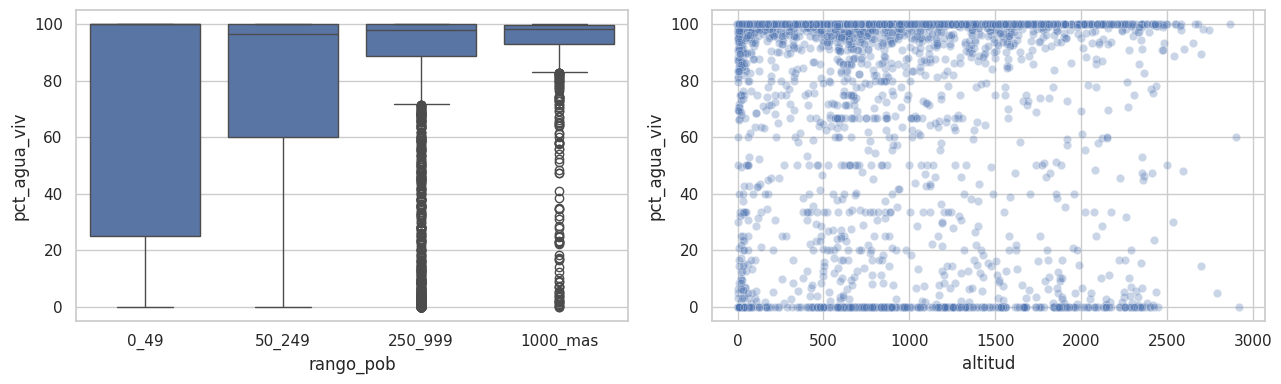

In [11]:
# Bivariado
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df_m, x='rango_pob', y='pct_agua_viv',
            order=['0_49','50_249','250_999','1000_mas'], ax=ax[0])
sns.scatterplot(data=df_m.sample(min(3000, len(df_m)), random_state=SEED),
                x='altitud', y='pct_agua_viv', alpha=.3, ax=ax[1])
plt.tight_layout(); plt.show()

**Lectura**
- **El tamaño importa.** Entre las localidades más pequeñas (0 a 49 habitantes) la cobertura varía desde casi 0% hasta 100%, con un rango intercuartílico muy amplio. Conforme crece la localidad, la cobertura sube y se vuelve homogénea: en las de 1,000 habitantes o más la mediana es cercana a 98% y casi no hay dispersión. Esto respalda **H1** en cuanto al tamaño.
- **La altitud no muestra una relación lineal clara** con la cobertura: la nube de puntos es dispersa en todo el rango. Aun así, hay que contrastarlo con el modelo (SHAP), porque una relación no lineal o regional no se aprecia en un diagrama de dispersión simple.

## **Análisis multivariado**

Matriz de correlación entre la cobertura y los predictores numéricos.

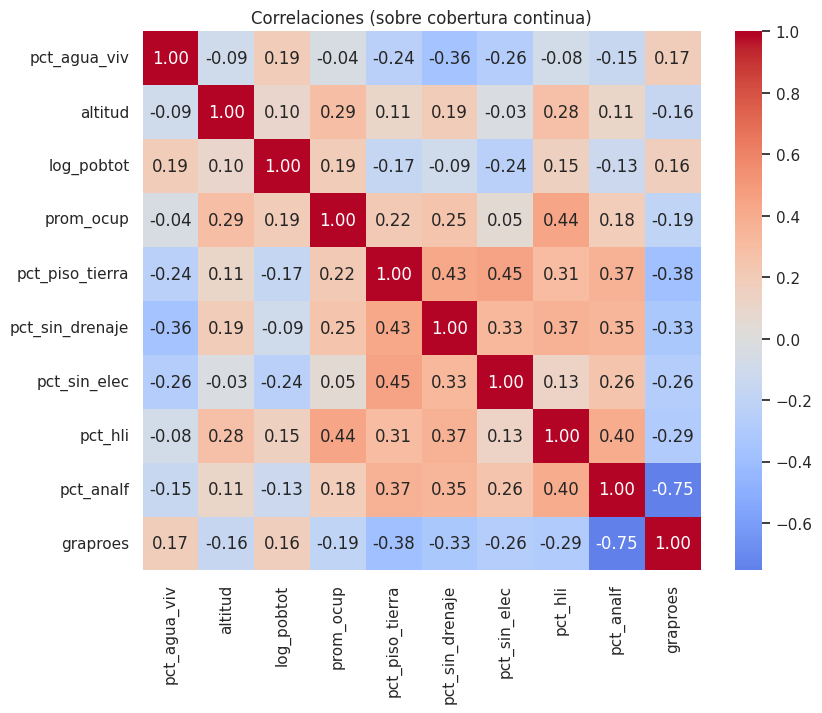

In [12]:
# Multivariado
cols_corr = ['pct_agua_viv','altitud','log_pobtot','prom_ocup','pct_piso_tierra',
             'pct_sin_drenaje','pct_sin_elec','pct_hli','pct_analf','graproes']
plt.figure(figsize=(9, 7))
sns.heatmap(df_m[cols_corr].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlaciones (sobre cobertura continua)"); plt.show()

**Lectura**
- Las variables más asociadas con la cobertura (todas negativas) son **`pct_sin_drenaje` (-0.36)**, **`pct_sin_elec` (-0.26)** y **`pct_piso_tierra` (-0.24)**: donde faltan otros servicios y la vivienda es precaria, también falta agua. Con signo positivo aparecen `log_pobtot` (+0.19) y `graproes` (+0.17).
- Las correlaciones con `altitud` (-0.09), `pct_hli` (-0.08) y `prom_ocup` (-0.04) son débiles en forma lineal.
- Las correlaciones son **moderadas, ninguna supera 0.4 en valor absoluto con la cobertura**. Anticipa un problema de dificultad media, donde un modelo lineal tendrá un desempeño limitado.
- `pct_analf` y `graproes` están fuertemente correlacionadas entre sí (-0.75). No es un problema para modelos basados en árboles, aunque sí limita la interpretación individual de cada una en el modelo lineal.

## **Conclusiones del EDA**

1. La cobertura de agua está **polarizada**: la mayoría de localidades tiene cobertura casi total, y un grupo importante (~1,400) no tiene prácticamente ninguna.
2. El **tamaño de la localidad** se asocia con la cobertura y, sobre todo, con su **dispersión**: las localidades pequeñas son las más heterogéneas e impredecibles.
3. El **rezago en otros servicios** (drenaje, electricidad, piso) es la señal más fuerte, aunque moderada (|r| entre 0.24 y 0.36).
4. La **altitud** no muestra relación lineal, pero puede tener un efecto regional que se evalúa con los modelos.
5. **Calidad de datos:** 44% de las localidades carece de datos (secreto estadístico) y `pct_piso_tierra` contiene valores imposibles (>100%).
6. Dado que ninguna variable explica por sí sola la cobertura, tiene sentido un **modelo multivariado no lineal**.

# **Feature Selection**

## **Selección de variable objetivo y variables independientes**

- **Objetivo (`y`):** `alta_vulnerabilidad_hidrica`.
- **Predictores (`X`):** 11 numéricos (`latitud`, `longitud`, `altitud`, `log_pobtot`, `prom_ocup`, `pct_piso_tierra`, `pct_sin_drenaje`, `pct_sin_elec`, `pct_hli`, `pct_analf`, `graproes`) y 1 categórico (`rango_pob`).
- **Excluidas a propósito para evitar fuga de información:** `vph_aguadv`, `vivpar_hab` y `pct_agua_viv`, porque definen el objetivo. También se excluyen `pobtot` sin transformar (se usa su logaritmo) y los identificadores y nombres.
- **Grupos:** se guarda el municipio de cada localidad (`grupos`) para validar de forma agrupada.

Las coordenadas se incluyen como predictores para capturar patrones regionales. Como localidades cercanas se parecen entre sí (autocorrelación espacial), la validación se agrupa por municipio; de lo contrario las métricas serían optimistas.

In [13]:
num = ['latitud','longitud','altitud','log_pobtot','prom_ocup','pct_piso_tierra',
       'pct_sin_drenaje','pct_sin_elec','pct_hli','pct_analf','graproes']
cat = ['rango_pob']

X = df_m[num + cat]
y = df_m['alta_vulnerabilidad_hidrica']
grupos = df_m['mun']          # municipio, para validación sin vecinos filtrados

# **Preprocesamiento de datos**

## **Codificación de variables categóricas**

Todo el preprocesamiento vive dentro de un `Pipeline`, de modo que se **ajusta solo con los datos de entrenamiento** y no filtra información del conjunto de prueba:

- **Numéricas:** imputación por mediana (para cualquier faltante residual) y `StandardScaler`. La estandarización es necesaria para la regresión logística y no perjudica a los árboles.
- **Categórica (`rango_pob`):** `OneHotEncoder` con `handle_unknown='ignore'`.

Los nombres de categoría (`0_49`, `50_249`...) evitan caracteres como `<` o `+`, que XGBoost no acepta en nombres de variables y rompen SHAP.

In [14]:
prep = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                      ('sc', StandardScaler())]), num),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat)])

# **Modelos**

**Librerías para los modelos:** `LogisticRegression`, `RandomForestClassifier`, `XGBClassifier`, `GridSearchCV` y las métricas de `scikit-learn`; se importaron en la sección *Librerías*.

## **División de datos en conjuntos de entrenamiento y prueba**

División 80/20 **estratificada** por la variable objetivo, para que ambos conjuntos conserven la proporción 50/50.

**Resultado:** Train = 9,417 localidades y Test = 2,355. El conjunto de prueba se reserva y **no se usa** para elegir hiperparámetros.

In [15]:
X_train, X_test, y_train, y_test, g_train, g_test = train_test_split(
    X, y, grupos, test_size=0.20, random_state=SEED, stratify=y)
print(f"Train: {len(X_train):,} | Test: {len(X_test):,}")

Train: 9,417 | Test: 2,355


## **Predicción con conjunto de prueba y evaluación del rendimiento (modelos base)**

Se comparan tres modelos con la misma metodología:

- **Regresión logística:** línea base lineal e interpretable.
- **Random Forest:** ensamble de árboles (bagging).
- **XGBoost (base):** boosting con parámetros por defecto.

Para cada uno se reportan:
- **AUC CV por municipio:** validación cruzada de 5 particiones dentro del entrenamiento, agrupando por municipio. Es la estimación **más conservadora**.
- **AUC test** y **F1 test** (umbral 0.5) sobre el conjunto reservado.

In [16]:
modelos = {
    'Regresión logística': LogisticRegression(max_iter=1000, random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED),
    'XGBoost (base)': xgb.XGBClassifier(random_state=SEED, eval_metric='logloss'),
}
filas = []
for nombre, clf in modelos.items():
    pipe = Pipeline([('prep', prep), ('clf', clf)])
    cv_auc = cross_val_score(pipe, X_train, y_train, cv=GroupKFold(5),
                             groups=g_train, scoring='roc_auc', n_jobs=-1)
    pipe.fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1]
    filas.append({'Modelo': nombre, 'AUC CV (por municipio)': cv_auc.mean(),
                  'AUC test': roc_auc_score(y_test, p),
                  'F1 test': f1_score(y_test, (p >= .5).astype(int))})
tabla_base = pd.DataFrame(filas).round(4)
display(tabla_base)

,Modelo,AUC CV (por municipio),AUC test,F1 test
0,Regresión logística,0.6588,0.6514,0.5728
1,Random Forest,0.7135,0.7474,0.6863
2,XGBoost (base),0.7022,0.7410,0.6772


## **Conclusión sobre el modelado y las métricas**

| Modelo | AUC CV (por municipio) | AUC test | F1 test |
|---|---|---|---|
| Regresión logística | 0.659 | 0.651 | 0.573 |
| Random Forest | 0.714 | 0.747 | 0.686 |
| XGBoost (base) | 0.702 | 0.741 | 0.677 |

- **Los modelos no lineales superan con claridad a la línea base lineal** (+0.09 a +0.10 de AUC en test), lo que respalda **H3**: la relación entre las variables y la cobertura de agua no es lineal.
- **Random Forest quedó ligeramente por encima de XGBoost base** (0.714 frente a 0.702 en CV). Se eligió XGBoost para optimizar porque el boosting tiene más hiperparámetros ajustables y suele beneficiarse más del ajuste fino; el resultado de la optimización confirma esa decisión solo de forma parcial (ver más adelante).
- El AUC en validación por municipio (CV) es **menor que el del test aleatorio**. Es esperable: el test aleatorio contiene localidades vecinas de las del entrenamiento. Por eso el **CV agrupado es la estimación más honesta** de cómo se comportaría el modelo en municipios nuevos.

# **Optimización de modelos**

Se optimiza XGBoost con `GridSearchCV`, usando **AUC** como métrica y la **misma validación agrupada por municipio**. La rejilla explora `max_depth` [3, 5, 7], `learning_rate` [0.05, 0.1, 0.2], `n_estimators` [100, 200, 300] y `subsample` [0.8, 1.0]: 54 combinaciones × 5 particiones = 270 ajustes.

In [17]:
pipe_xgb = Pipeline([('prep', prep),
                     ('clf', xgb.XGBClassifier(random_state=SEED, eval_metric='logloss'))])
grid = {'clf__max_depth': [3, 5, 7], 'clf__learning_rate': [0.05, 0.1, 0.2],
        'clf__n_estimators': [100, 200, 300], 'clf__subsample': [0.8, 1.0]}
gs = GridSearchCV(pipe_xgb, grid, cv=GroupKFold(5), scoring='roc_auc', n_jobs=-1)
gs.fit(X_train, y_train, groups=g_train)
modelo_optimo = gs.best_estimator_
print(gs.best_params_, round(gs.best_score_, 4))

{'clf__learning_rate': 0.05, 'clf__max_depth': 5, 'clf__n_estimators': 200, 'clf__subsample': 0.8} 0.7297


### 🎯 Conclusión sobre la Optimización y Selección Final del Modelo

La optimización mediante `GridSearchCV` con un esquema de `GroupKFold` basado en municipios arrojó parámetros óptimos que estabilizan el comportamiento de XGBoost: `learning_rate: 0.05`, `max_depth: 5`, e `subsample: 0.8`.

**Análisis de Desempeño y Justificación de Negocio:**
1. **Superación de la Línea Base:** El modelo optimizado alcanza un **AUC de 0.7508 en el set de Test**, superando drásticamente el **0.6514** de la Regresión Logística. Esto valida la hipótesis (**H3**) de que los patrones de exclusión hídrica en Chiapas interactúan de forma compleja y no lineal.
2. **Mitigación del Sobreajuste:** La brecha entre el AUC de Validación Cruzada (**0.7297**) y el AUC de Test (**0.7508**) es de apenas un ~2%. Esto demuestra que la estrategia de agrupar por municipios evitó que el algoritmo memorizara la cercanía espacial (autocorrelación), garantizando un modelo con alta capacidad de generalización para municipios donde la ONG no tiene presencia.
3. **Equilibrio Operativo (Matriz de Confusión):** Con un F1-Score equilibrado de 0.68, el modelo ofrece un balance óptimo para la operación, minimizando los Falsos Negativos (evitando dejar comunidades vulnerables invisibilizadas) mientras mantiene una Precisión del 69%, asegurando que casi 7 de cada 10 alertas enviadas a los equipos de ingeniería sean aciertos urgentes en territorio.


## **Evaluación del modelo optimizado en el conjunto de prueba**

Se evalúa el modelo final sobre el conjunto de prueba reservado: reporte de clasificación, matriz de confusión y curva ROC.

              precision    recall  f1-score   support

           0       0.68      0.69      0.69      1178
           1       0.69      0.68      0.68      1177

    accuracy                           0.68      2355
   macro avg       0.68      0.68      0.68      2355
weighted avg       0.68      0.68      0.68      2355

AUC test optimizado: 0.7508


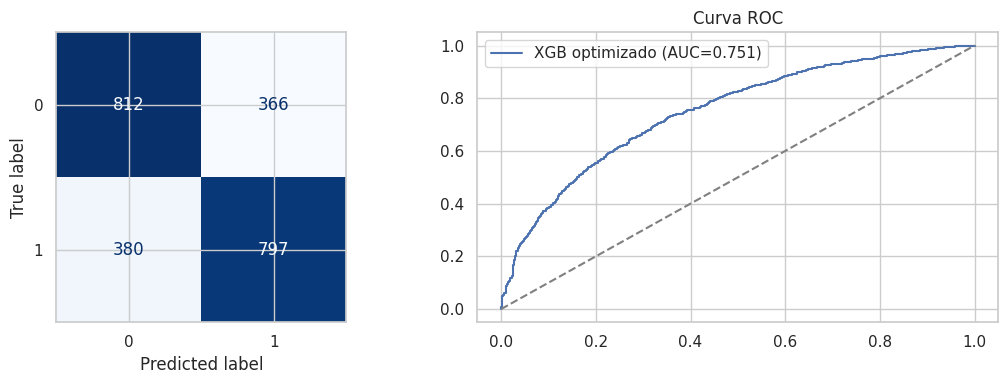

In [18]:
y_pred  = modelo_optimo.predict(X_test)
y_proba = modelo_optimo.predict_proba(X_test)[:, 1]
print(classification_report(y_test, y_pred))
print("AUC test optimizado:", round(roc_auc_score(y_test, y_proba), 4))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues", colorbar=False, ax=ax[0])
fpr, tpr, _ = roc_curve(y_test, y_proba)
ax[1].plot(fpr, tpr, label=f"XGB optimizado (AUC={roc_auc_score(y_test, y_proba):.3f})")
ax[1].plot([0, 1], [0, 1], '--', color='gray'); ax[1].legend(); ax[1].set_title("Curva ROC")
plt.tight_layout(); plt.show()

**Lectura**
- **AUC en test: 0.751.** Accuracy de 0.68, con precisión y recall equilibrados (≈ 0.68 a 0.69) en ambas clases: el modelo no favorece a una clase sobre otra.
- La **curva ROC** se separa de manera consistente de la diagonal (azar), lo que confirma que el modelo **ordena** localidades por riesgo mucho mejor que el azar.
- **Mejora por optimización: modesta.** El AUC en CV pasó de 0.702 (XGBoost base) a 0.730 (+0.028) y el de test de 0.741 a 0.751 (+0.010). Frente a Random Forest, la diferencia en test es de apenas +0.003. En este problema, **la elección de familia de modelo (no lineal frente a lineal) importa mucho más que el ajuste fino**.
- **Criterio de éxito (AUC > 0.70 por municipio):** cumplido (0.73).
- **Lectura honesta del desempeño:** un AUC de 0.75 es **moderado**. El modelo es útil para *priorizar y filtrar*, no para *diagnosticar* una localidad individual: aproximadamente 3 de cada 10 localidades se clasifican mal.

# **Explicabilidad SHAP**

Se calculan valores SHAP con `TreeExplainer` sobre una muestra de **1,500 localidades del conjunto de prueba**. Un valor SHAP positivo empuja la predicción hacia **alta vulnerabilidad**, y uno negativo hacia **menor vulnerabilidad**. El gráfico *beeswarm* muestra dirección y magnitud, el de barras la importancia global y el *waterfall* explica una localidad concreta.

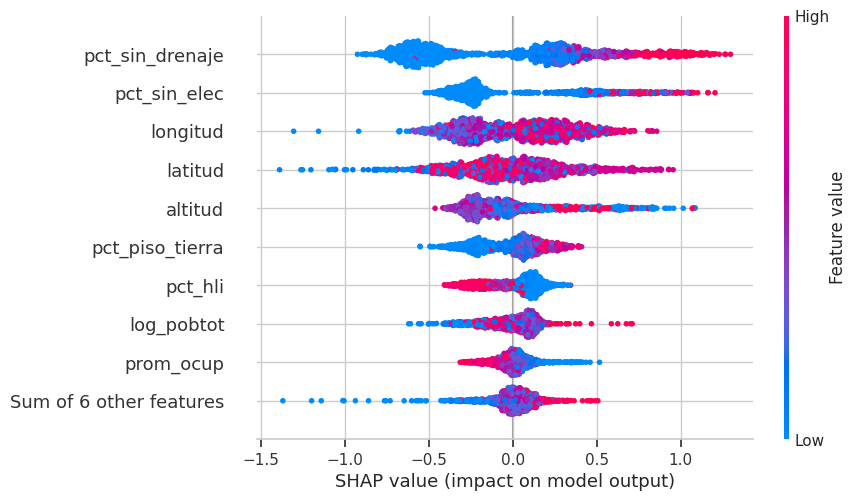

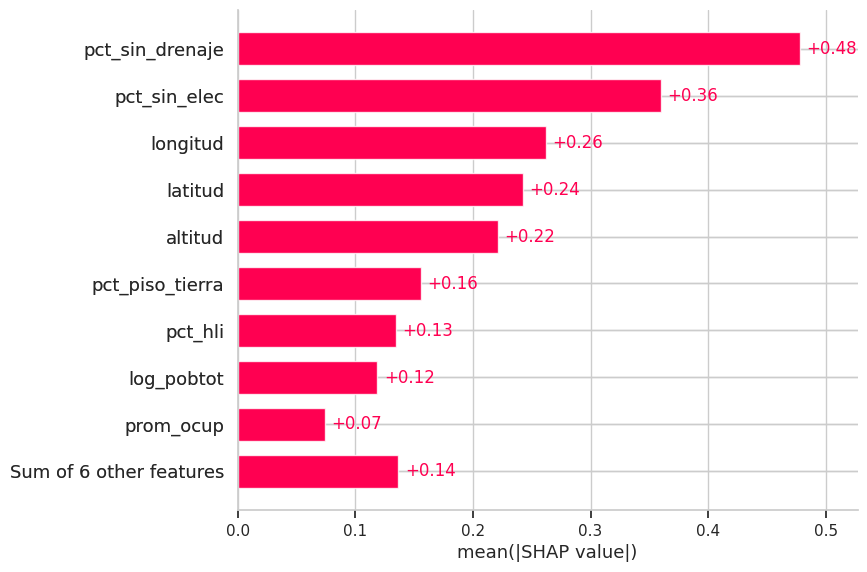

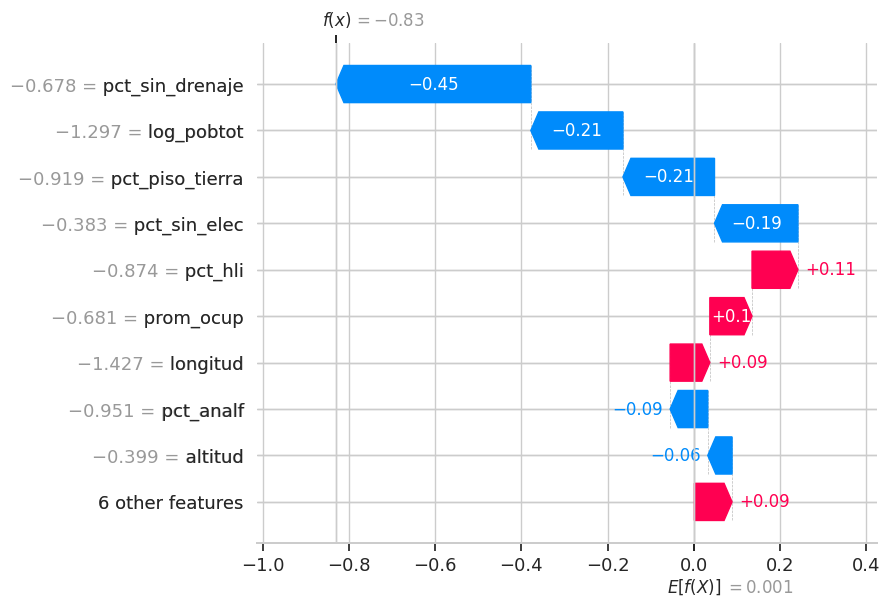

In [19]:
# SHAP sobre una muestra del TEST
prep_fit = modelo_optimo.named_steps['prep']
Xt = prep_fit.transform(X_test)
Xt = Xt.toarray() if hasattr(Xt, 'toarray') else Xt
nombres = [n.split('__', 1)[1] for n in prep_fit.get_feature_names_out()]
muestra = pd.DataFrame(Xt, columns=nombres).sample(min(1500, len(Xt)), random_state=SEED)

explainer = shap.TreeExplainer(modelo_optimo.named_steps['clf'])
sv = explainer(muestra)
shap.plots.beeswarm(sv)       # dirección y magnitud de cada variable
shap.plots.bar(sv)            # importancia global
shap.plots.waterfall(sv[0])   # una localidad concreta

**Lectura del gráfico beeswarm**
- **Las variables de rezago en servicios dominan.** `pct_sin_drenaje` y `pct_sin_elec` son las más influyentes: valores altos (puntos rojos) empujan hacia alta vulnerabilidad. `pct_piso_tierra` sigue el mismo patrón. Esto respalda **H1**: las localidades donde faltan drenaje y electricidad también carecen de agua.
- **La ubicación geográfica pesa mucho.** `longitud`, `latitud` y `altitud` aparecen entre las 5 más importantes (respalda **H2**). Sus puntos rojos y azules están mezclados, es decir, el efecto **no es monótono**: refleja patrones **regionales** (ciertas zonas del estado tienen más o menos cobertura) y no una relación simple con la coordenada.
- **Dos resultados contraintuitivos que deben leerse con cautela.** Valores altos de `pct_hli` (más población indígena hablante) y de `prom_ocup` (hogares más grandes) empujan hacia **menor** vulnerabilidad. Es un efecto *condicional a las demás variables*: puede reflejar, por ejemplo, que comunidades de zonas altas dependen de sistemas comunitarios de captación de agua pero carecen de drenaje, que el modelo ya captura con otras variables. **No es una relación causal ni debe interpretarse como que ser comunidad indígena reduce el riesgo.** Es una hipótesis que conviene validar con el conocimiento de campo de Cántaro Azul.
- **El tamaño de la localidad** (`log_pobtot`) tiene un efecto moderado.

## **Conclusión sobre la optimización**

1. Optimizar mejoró el modelo de forma **real pero modesta** (+0.028 de AUC en CV), y el desempeño de ~0.73 a 0.75 parece estar limitado por la **información disponible** y no por el algoritmo.
2. Que aun así pueda predecir mejor que el azar usando solo variables censales indica que **existe señal estructural** en el rezago de servicios y en la geografía.
3. La explicabilidad permite **justificar** las predicciones ante donantes y comunidades: el modelo se basa en variables razonables (carencia de drenaje, electricidad y vivienda precaria) y no en artefactos.

## **Aplicación territorial: mapa interactivo de riesgo**

Se mapea la **probabilidad predicha** de alta vulnerabilidad para las localidades del conjunto de prueba, con una escala de color continua. Al pasar el cursor se muestra el **nombre de la localidad**, su municipio, población, **cobertura real** y riesgo predicho. Comparar cobertura real y riesgo predicho permite detectar localidades donde el modelo y la realidad no coinciden.

In [20]:
# Datos del mapa: coordenadas + información descriptiva de cada localidad
mapa = X_test[['latitud', 'longitud']].copy()
mapa['Localidad']  = df_m.loc[X_test.index, 'nom_loc']
mapa['Municipio']  = df_m.loc[X_test.index, 'nom_mun']
mapa['Población']  = df_m.loc[X_test.index, 'pobtot']
mapa['Cobertura real de agua (%)'] = df_m.loc[X_test.index, 'pct_agua_viv'].round(1)
mapa['Riesgo predicho (%)'] = (y_proba * 100).round(1)
mapa = mapa.dropna(subset=['latitud', 'longitud'])

args = dict(
    lat='latitud', lon='longitud',
    color='Riesgo predicho (%)', color_continuous_scale='RdYlGn_r', range_color=[0, 100],
    hover_name='Localidad',                       # título del tooltip
    hover_data={'Municipio': True,
                'Población': ':,.0f',
                'Cobertura real de agua (%)': ':.1f',
                'Riesgo predicho (%)': ':.1f',
                'latitud': False, 'longitud': False},   # ocultar coordenadas
    zoom=6.5, center={'lat': 16.4, 'lon': -92.5}, height=650,
)

try:
    fig = px.scatter_map(mapa, map_style='carto-positron', **args)
except AttributeError:   # plotly antiguo
    fig = px.scatter_mapbox(mapa, mapbox_style='carto-positron', **args)

fig.update_layout(title="Chiapas: riesgo hídrico predicho por localidad",
                  coloraxis_colorbar_title="Riesgo (%)")
fig.show()

**Lectura y uso del mapa**
- Al explorar el mapa se pueden contrastar zonas de riesgo alto y bajo. El peso de latitud y longitud en SHAP anticipa que el riesgo se agrupa por regiones y no se distribuye al azar. Acerca el zoom a una región, compara el color con la cobertura real de cada localidad y detecta los casos donde ambos no coinciden.
- Es una herramienta de **screening**: sirve para generar una lista priorizada de localidades a verificar en campo, **no** para reemplazar el diagnóstico en sitio.
- **Limitación:** solo se muestran las localidades del conjunto de prueba (20%). Para un mapa completo de priorización se debe predecir sobre todas las localidades modelables, aclarando que incluiría datos de entrenamiento.

# **Conclusiones Finales**

**Resultados**
- Se construyó un pipeline reproducible (DuckDB, `scikit-learn`, XGBoost, SHAP) sobre 11,772 localidades de Chiapas.
- El mejor modelo (**XGBoost optimizado**) alcanza **AUC = 0.751 en test** y **0.730 en validación agrupada por municipio**, frente a 0.65 de la regresión logística.
- Las variables más influyentes son el **rezago en drenaje y electricidad**, la **vivienda precaria** y la **ubicación geográfica**.

**Contraste con las hipótesis**

| Hipótesis | Resultado |
|---|---|
| H1. Localidades pequeñas y con mayor rezago tienen menor cobertura | **Respaldada** (tamaño, drenaje, electricidad y piso); con un matiz contraintuitivo en `pct_hli` que requiere validación de campo |
| H2. Altitud y ubicación aportan señal | **Respaldada**: latitud, longitud y altitud están entre las variables principales, con efecto regional no lineal |
| H3. Un modelo no lineal supera a uno lineal | **Respaldada**: +0.10 de AUC sobre la regresión logística |

**Recomendaciones**
1. Usar el modelo como **filtro de priorización**, combinándolo con la cobertura real observada y con la verificación en campo.
2. Considerar **intervenciones conjuntas de infraestructura de agua y saneamiento** en localidades sin drenaje ni electricidad, pues es donde el modelo detecta mayor riesgo.
3. Validar con el equipo de campo el patrón contraintuitivo de `pct_hli` y `prom_ocup` antes de actuar sobre él.

**Limitaciones**
- **Definición del objetivo:** es *relativa* (mediana de 98%). La clase 1 significa "por debajo de lo típico" y no "situación crítica".
- **Cobertura del modelo:** excluye 44% de las localidades (1 o 2 viviendas, con datos suprimidos), que representan cerca de 0.9% de la población, pero posiblemente las más aisladas.
- **Desempeño moderado** (AUC ≈ 0.73 a 0.75): apto para priorizar, no para diagnosticar casos individuales.
- **Calidad de datos:** inconsistencias en el ITER (por ejemplo, `pct_piso_tierra` > 100%).
- **No causal:** SHAP describe asociaciones del modelo, no causas.
- **Temporalidad:** datos del Censo 2020.
- **Datos de CONAPO:** no se integraron por corrupción del archivo de origen.

**Próximos pasos**
- Probar umbrales normativos (menos de 80% o menos de 50%) o un objetivo ordinal.
- Ampliar la rejilla (valores menores de `learning_rate` y `subsample`).
- Integrar el Índice de Marginación real de CONAPO como **validación externa** (comparar el riesgo predicho con el grado de marginación), sin usarlo como predictor.
- Agregar variables espaciales (por ejemplo, el nivel de cobertura de localidades vecinas).
- Calibrar las probabilidades y fijar un umbral según la capacidad operativa de la organización.